In [1]:
from ipaddress import summarize_address_range

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
titanic = pd.read_csv("data/Titanic-Dataset.csv")

In [3]:
titanic.shape

(891, 12)

In [4]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
titanic.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [9]:
print(titanic["Survived"].value_counts(), end="\n\n")
print(titanic["Pclass"].value_counts(), end="\n\n")
print(titanic["Sex"].value_counts(), end="\n\n")
print(titanic["Age"].value_counts(), end="\n\n")
print(titanic["Embarked"].value_counts(), end="\n\n")

Survived
0    549
1    342
Name: count, dtype: int64

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Sex
male      577
female    314
Name: count, dtype: int64

Age
24.00    30
22.00    27
18.00    26
19.00    25
28.00    25
         ..
36.50     1
55.50     1
0.92      1
23.50     1
74.00     1
Name: count, Length: 88, dtype: int64

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64



In [10]:
print(titanic["Age"].mean(), end="\n\n")
print(titanic["Fare"].median(), end="\n\n")
print(titanic["Age"].mode(), end="\n\n")

29.69911764705882

14.4542

0    24.0
Name: Age, dtype: float64



Text(0, 0.5, 'Number of passengers')

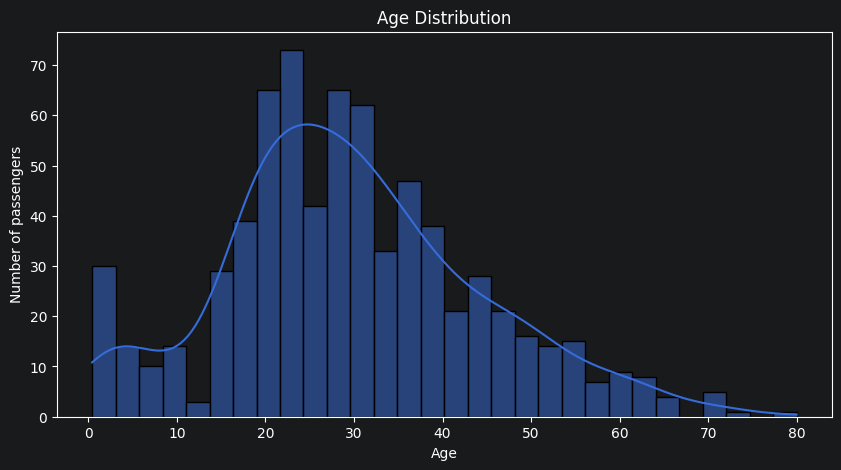

In [11]:
plt.figure(figsize=(10,5))
sns.histplot(data=titanic, x="Age", bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of passengers")

right-skewed distribution.
This means that the mean is grater than median

In [12]:
print(f'Mean {titanic["Age"].mean()}')
print(f'Median {titanic["Age"].median()}')
print(f'Mode {titanic["Age"].mode()}')


Mean 29.69911764705882
Median 28.0
Mode 0    24.0
Name: Age, dtype: float64


In [13]:
titanic.groupby(["Sex", "Pclass"])["Age"].agg(["count", "mean", "median"])

count       mean  median
Sex    Pclass                          
female 1          85  34.611765    35.0
       2          74  28.722973    28.0
       3         102  21.750000    21.5
male   1         101  41.281386    40.0
       2          99  30.740707    30.0
       3         253  26.507589    25.0

In [14]:
titanic.groupby(["Sex", "Pclass"])["Age"].agg(total="size", known="count", missing=lambda x: x.isna().sum())

total  known  missing
Sex    Pclass                       
female 1          94     85        9
       2          76     74        2
       3         144    102       42
male   1         122    101       21
       2         108     99        9
       3         347    253       94

In [15]:
titanic["Age_filled"] = titanic["Age"].fillna(titanic.groupby(["Sex", "Pclass"])["Age"].transform("median"))
print(titanic["Age_filled"].isnull().sum())
print(titanic["Age"].isnull().sum())


0
177


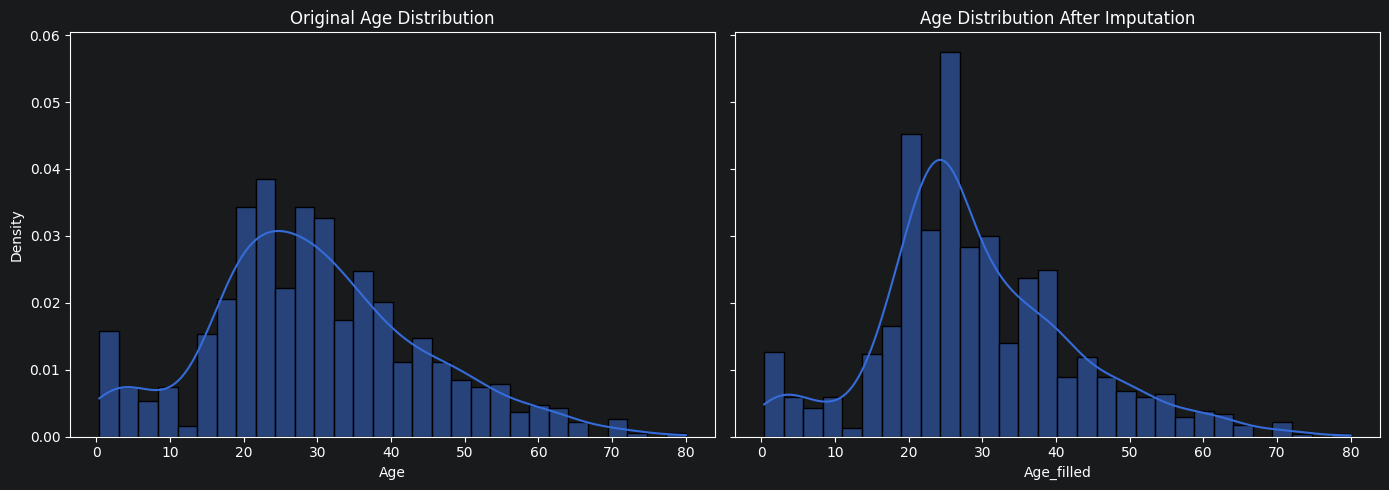

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
sns.histplot(
    data=titanic,
    x="Age",
    bins=30,
    kde=True,
    stat="density",
    ax=axes[0]
)

axes[0].set_title("Original Age Distribution")

sns.histplot(
    data=titanic,
    x="Age_filled",
    bins=30,
    kde=True,
    stat="density",
    ax=axes[1]
)

axes[1].set_title("Age Distribution After Imputation")

plt.tight_layout()
plt.show()

Missing age values were imputed using median ages grouped by Sex and Pclass. After imputation, the dataset contains no missing values in the Age_filled column. The overall age distribution remains similar, but additional peaks appear due to repeated median values assigned to passengers within the same groups.

In [17]:
titanic.groupby(["Sex", "Survived"])["Survived"].agg(["count"])

count
Sex    Survived       
female 0            81
       1           233
male   0           468
       1           109

In [18]:
survived_rate_byGender = titanic.groupby("Sex")["Survived"].agg(["count", "sum", "mean"])
survived_rate_byGender['survived_rate'] = (survived_rate_byGender['mean']*100).round(2)
survived_rate_byGender

,count,sum,mean,survived_rate
Sex,,,,
female,314,233,0.742038,74.20
male,577,109,0.188908,18.89


<Axes: title={'center': 'Surviving rate by Gender'}, xlabel='Gender', ylabel='Survived Rate (%)'>

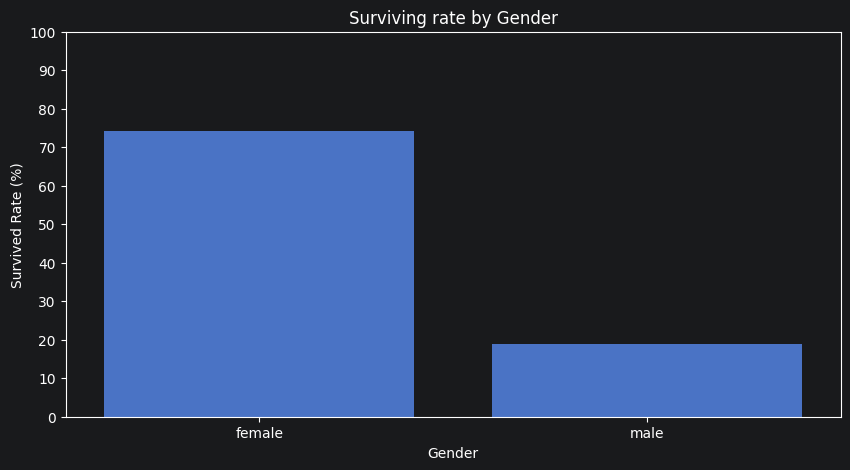

In [19]:
plt.figure(figsize=(10,5))
plt.title("Surviving rate by Gender")
plt.ylabel("Survived Rate (%)")
plt.xlabel("Gender")
plt.ylim(0,100)
plt.yticks(range(0, 101, 10))
sns.barplot(data=survived_rate_byGender, x="Sex", y="survived_rate")

The analysis shows that the female survival rate is about 75%, and male survival rate is about 20%. The female survival rate is about four times more than the male survival rate.

In [20]:
titanic.groupby("Pclass")["Survived"].agg(["count", "sum", "mean"])

,count,sum,mean
Pclass,,,
1,216,136,0.629630
2,184,87,0.472826
3,491,119,0.242363


In [21]:
survival_rate_byPclass = titanic.groupby("Pclass")["Survived"].agg(["count", "sum", "mean"])
survival_rate_byPclass["survival_rate"] = survival_rate_byPclass["mean"]*100
survival_rate_byPclass

,count,sum,mean,survival_rate
Pclass,,,,
1,216,136,0.629630,62.962963
2,184,87,0.472826,47.282609
3,491,119,0.242363,24.236253


<Axes: title={'center': 'Survival Rate By Pclass'}, xlabel='Pclass', ylabel='Survival Rate (%)'>

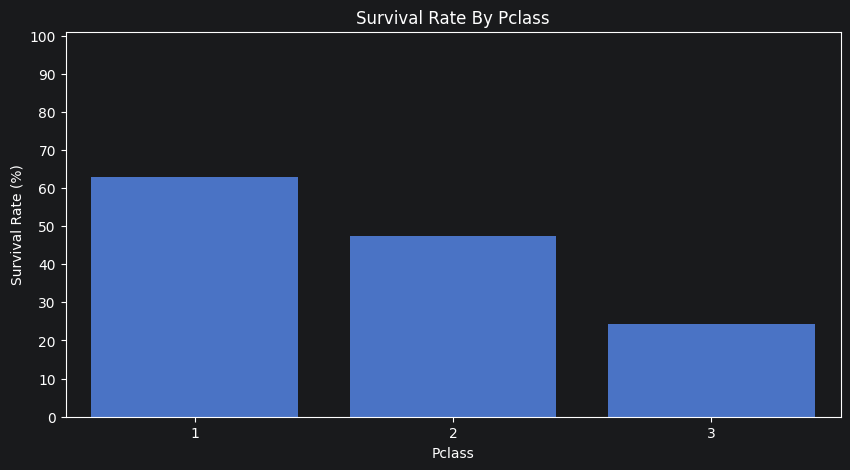

In [22]:
plt.figure(figsize=(10,5))
plt.title("Survival Rate By Pclass")
plt.ylabel("Survival Rate (%)")
plt.xlabel("Pclass")
plt.ylim(1, 101)
plt.yticks(range(0, 101, 10))
sns.barplot(data=survival_rate_byPclass, x="Pclass", y="survival_rate")

The analysis shows the difference between the survival rate of the passengers of different Pclasses.
About 63% passengers of 1 Pclass survived, approximately 48% passengers of the 2 Pclass survived, and approximately 25% passengers of the 3 Pclass survived.
This diagram shows that the passenger survival rate increases depends on the Passenger Class.

In [23]:
titanic.groupby(["Sex", "Pclass"])["Survived"].agg(["count", "sum", "mean"])

count  sum      mean
Sex    Pclass                      
female 1          94   91  0.968085
       2          76   70  0.921053
       3         144   72  0.500000
male   1         122   45  0.368852
       2         108   17  0.157407
       3         347   47  0.135447

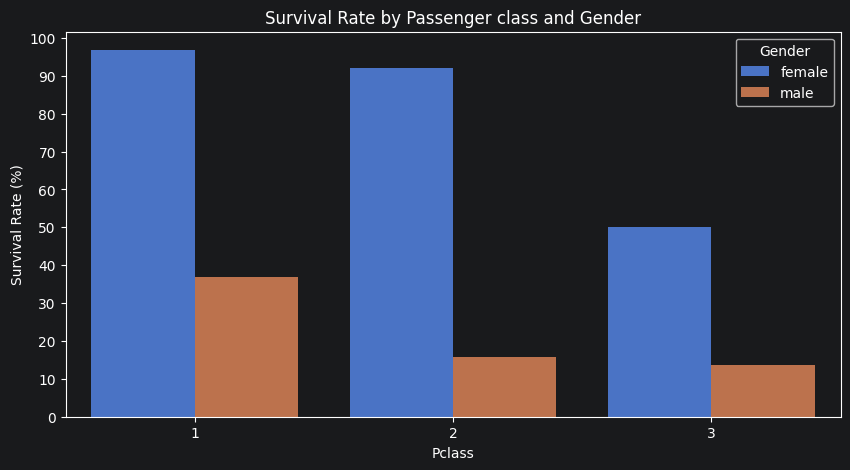

In [24]:
survived_by_sex_pclass = titanic.groupby(["Sex", "Pclass"])["Survived"].mean().reset_index()
survived_by_sex_pclass['Survival Rate'] = survived_by_sex_pclass["Survived"] * 100
plt.figure(figsize=(10,5))
sns.barplot(data=survived_by_sex_pclass, x="Pclass", y="Survival Rate", hue="Sex")
plt.yticks(range(0, 101, 10))
plt.ylabel("Survival Rate (%)")
plt.xlabel("Pclass")
plt.title("Survival Rate by Passenger class and Gender")
plt.legend(title="Gender")
plt.show()

The analysis shows the male and female survival rate depends on their Passenger Class. The female survival rate of the 1 and 2 class is greater than 90% (~97% 1 class, ~92% 2 class), and the lowest female survival rate is in the 3 class (50%). The male survival rate of the 1 class is ~37%, the male survival rate of the 2 class is ~16%, and the lowest male survival rate of the 3 class is ~13,5%.
This means that almost all female from 1 and 2 class survived, but the 3 class only half was survived, and the male survival rate is extremely lower than the female.

In [25]:
bins=[0,12,17,35,59,100]
labels=['Children', 'Teenagers', 'Young Adults', 'Adults', 'Seniors']
titanic['Age_group'] = pd.cut(titanic['Age_filled'], bins=bins, labels=labels, include_lowest=True)
titanic['Age_group'].value_counts().sort_index()

Age_group
Children         69
Teenagers        44
Young Adults    540
Adults          212
Seniors          26
Name: count, dtype: int64

In [26]:
titanic.groupby("Age_group")["Survived"].agg(["count", "sum", "mean"])

/var/folders/kb/9np2bwfx18z2bg2nxt6y8yx80000gn/T/ipykernel_51580/4222371802.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby("Age_group")["Survived"].agg(["count", "sum", "mean"])


,count,sum,mean
Age_group,,,
Children,69,40,0.579710
Teenagers,44,21,0.477273
Young Adults,540,193,0.357407
Adults,212,81,0.382075
Seniors,26,7,0.269231


/var/folders/kb/9np2bwfx18z2bg2nxt6y8yx80000gn/T/ipykernel_51580/2254083400.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  survival_rate_AgeGroup = titanic.groupby("Age_group")["Survived"].mean().reset_index()


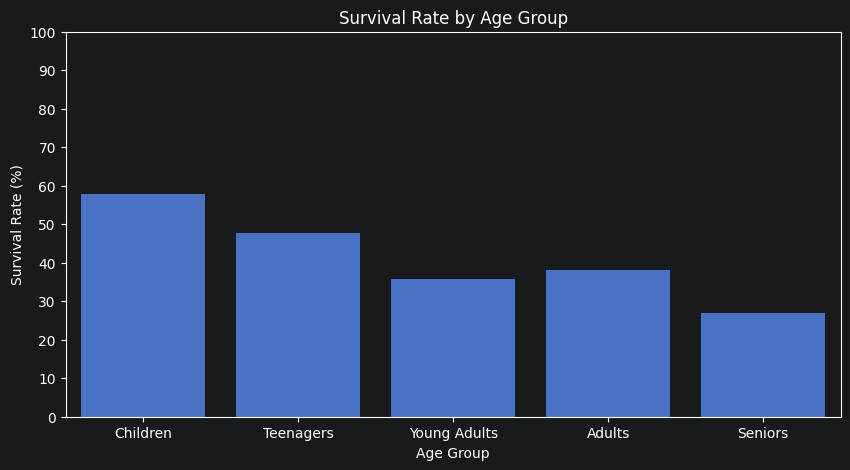

In [27]:

survival_rate_AgeGroup = titanic.groupby("Age_group")["Survived"].mean().reset_index()
survival_rate_AgeGroup['Survival Rate'] = survival_rate_AgeGroup["Survived"]*100
plt.figure(figsize=(10,5))
sns.barplot(data=survival_rate_AgeGroup, x="Age_group", y="Survival Rate")
plt.yticks(range(0, 101, 10))
plt.ylabel("Survival Rate (%)")
plt.xlabel("Age Group")
plt.title("Survival Rate by Age Group")
plt.show()

The analysis shows the diffenerce in survival rates across five age groups: Children, Teenagers, Young Adults, Adults, Seniors.
 The children survival rate is the highest ~58%, the teenagers survival rate is ~48%, the young adults survival rate is ~36%, the adults survival rate is 38%, the seniors survival rate is the lowest ~27%.
This means that the lower age the more survival rate, but young adults and adults survival rates are almost the same.

In [28]:
titanic.groupby("Survived")["Fare"].agg(["count", "sum", "mean", "median", "max", "min"])

,count,sum,mean,median,max,min
Survived,,,,,,
0,549,12142.7199,22.117887,10.5,263.0000,0.0
1,342,16551.2294,48.395408,26.0,512.3292,0.0


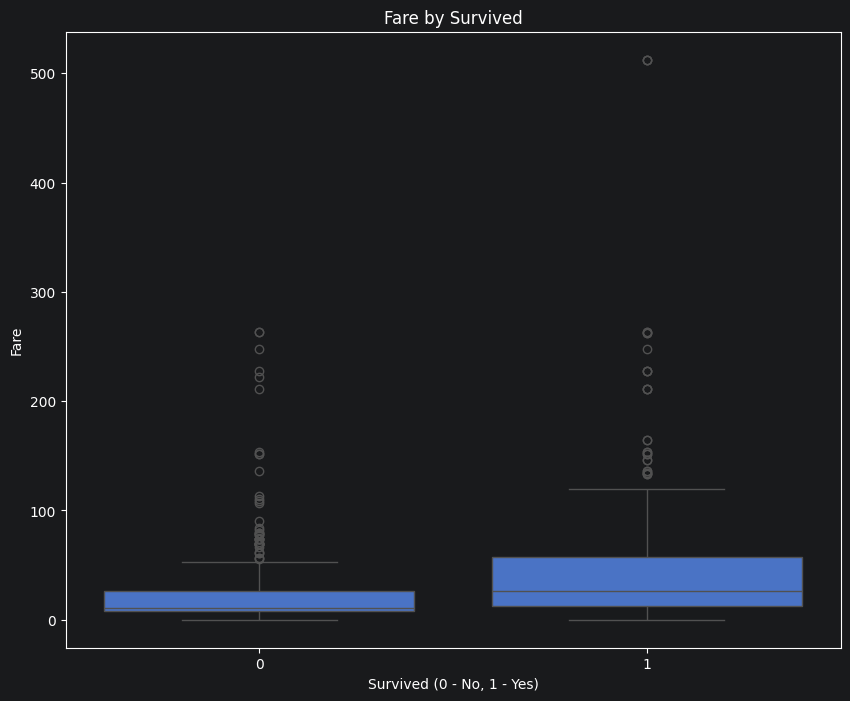

In [29]:
plt.figure(figsize=(10,8))
sns.boxplot(data=titanic, x="Survived", y="Fare")
plt.xlabel("Survived (0 - No, 1 - Yes)")
plt.ylabel("Fare")
plt.title("Fare by Survived")
plt.show()

Passengers who survived generally paid higher ticket fares than those who did not survive.

The median fare among survivors was 26.0, compared to 10.5 among non-survivors. The average fare was also higher among survivors (48.40 vs. 22.12).

The box plot shows that the distribution of fares among survivors is shifted towards higher values. This suggests an association between higher ticket fares and a greater chance of survival.

However, this relationship may be influenced by passenger class, since first-class tickets were generally more expensive.

In [30]:
titanic.groupby(["Pclass", "Survived"])["Fare"].agg(["count", "mean", "median", "max", "min"])

count       mean   median       max      min
Pclass Survived                                              
1      0            80  64.684007  44.7500  263.0000   0.0000
       1           136  95.608029  77.9583  512.3292  25.9292
2      0            97  19.412328  13.0000   73.5000   0.0000
       1            87  22.055700  21.0000   65.0000  10.5000
3      0           372  13.669364   8.0500   69.5500   0.0000
       1           119  13.694887   8.5167   56.4958   0.0000

After the analysis of the survival rate by the fare, we see the difference in separate Passenger classes. In first class the survivors had the median fare (77.9) and the mean fare (95.6) greater than the non-survivors median fare (44.7) and mean fare (64.6). In second class the difference between survivors and non-survivors is smaller (survivors median fare 21 and mean fare 22, non-survivors median fare 13 and mean fare 19.4). But in the third class there is no difference between survivors and non-survivors.

The suggestion that the relationship between ticket fare and survivor partially associated with passenger class. The difference was more noticeable in first class

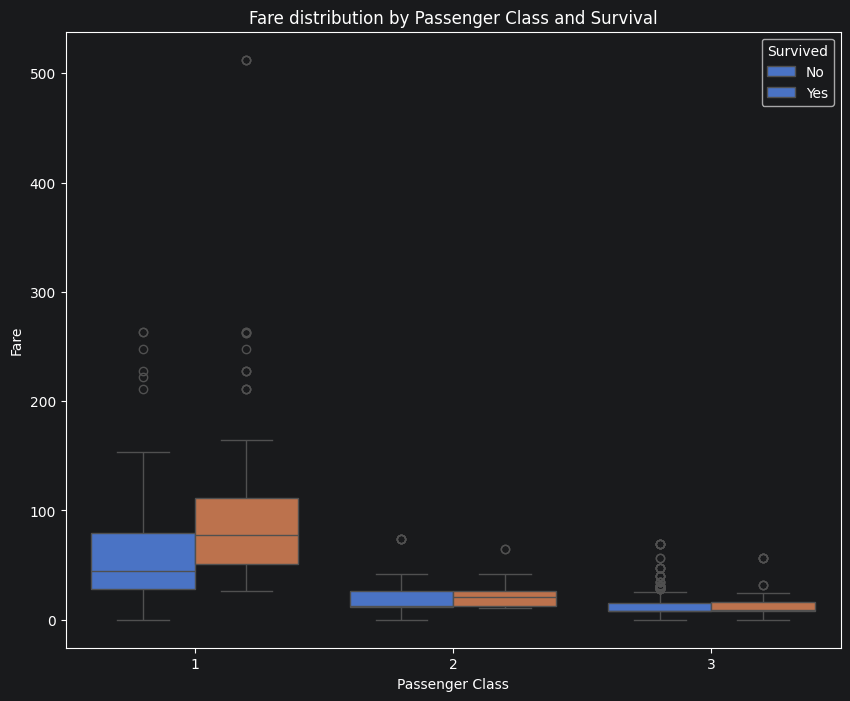

In [33]:
plt.figure(figsize=(10,8))
sns.boxplot(data=titanic, x="Pclass", y="Fare", hue="Survived")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.title("Fare distribution by Passenger Class and Survival")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()

In [36]:
titanic.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_filled,Age_group
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,22.0,Young Adults
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,38.0,Adults
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,26.0,Young Adults
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,35.0,Young Adults
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,35.0,Young Adults
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q,25.0,Young Adults
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,54.0,Adults
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S,2.0,Children
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S,27.0,Young Adults
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C,14.0,Teenagers


In [53]:
titanic['Family Size'] = titanic['SibSp'] + titanic['Parch']
survival_by_family = titanic.groupby("Family Size")["Survived"].agg(["count", "sum", "mean"]).reset_index()
survival_by_family['Survival Rate (%)'] = survival_by_family['mean'] * 100
survival_by_family

,Family Size,count,sum,mean,Survival Rate (%)
0,0,537,163,0.303538,30.353818
1,1,161,89,0.552795,55.279503
2,2,102,59,0.578431,57.843137
3,3,29,21,0.724138,72.413793
4,4,15,3,0.200000,20.000000
5,5,22,3,0.136364,13.636364
6,6,12,4,0.333333,33.333333
7,7,6,0,0.000000,0.000000
8,10,7,0,0.000000,0.000000


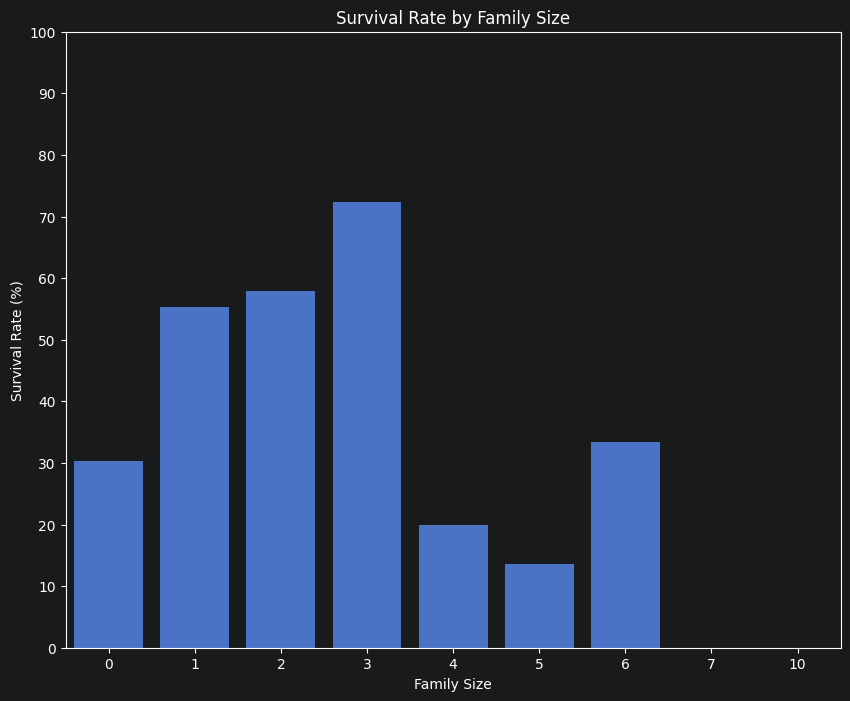

In [54]:
plt.figure(figsize=(10,8))
sns.barplot(data=survival_by_family, x="Family Size", y="Survival Rate (%)")
plt.yticks(range(0, 101, 10))
plt.ylabel("Survival Rate (%)")
plt.xlabel("Family Size")
plt.title("Survival Rate by Family Size")
plt.show()

The analysis shows the correlation between survival rate and the family size.

The highest survival rate shows the passengers with 1 (55.2%), 2 (57,8%), and 3 (72.4%) family members. However, the passengers traveling alone has survival rate 30.3% and passengers with larger families has the lowest survival rates.

These results should be interpreted carefully, because some family-size groups have few passengers.

In [55]:
titanic['Travel Alone'] = titanic['Family Size'].apply(lambda x: "Alone" if x == 0 else "Not Alone")
titanic['Travel Alone'].value_counts().sort_index()

Travel Alone
Alone        537
Not Alone    354
Name: count, dtype: int64

In [57]:
survival_by_travel = titanic.groupby("Travel Alone")["Survived"].agg(["count", "sum", "mean"])
survival_by_travel['Survival Rate (%)'] = survival_by_travel["mean"]*100
survival_by_travel

,count,sum,mean,Survival Rate (%)
Travel Alone,,,,
Alone,537,163,0.303538,30.353818
Not Alone,354,179,0.505650,50.564972


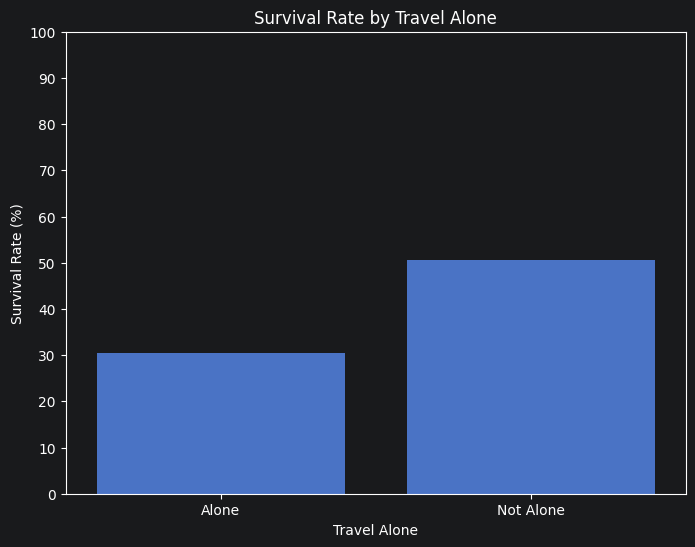

In [61]:
plt.figure(figsize=(8,6))
sns.barplot(data=survival_by_travel, x="Travel Alone", y="Survival Rate (%)")
plt.yticks(range(0, 101, 10))
plt.ylabel("Survival Rate (%)")
plt.xlabel("Travel Alone")
plt.title("Survival Rate by Travel Alone")
plt.show()

The analysis of the survival rate by the traveling alone/not alone.

The analysis shows that passengers who travels alone has lower survival rate (30.3%) than the passengers who travels with family with survival rate 50.5%